In [ ]:
!pip install tensorflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 620.7/620.7 MB 720.8 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.5/57.5 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.5/24.5 MB 56.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 67.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 69.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 225.0/225.0 kB 18.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.5/72.5 kB 6.7 MB/s eta 0:00:00


In [ ]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import load_img, img_to_array

from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# versi
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.19.0


**Menyiapkan Data**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Load dataset dan buat dataframe

data_dir = "/content/drive/MyDrive/Dataset"

filepaths = []
labels = []
ids = []

# Ekstensi valid
valid_ext = [".jpg", ".jpeg", ".png"]

# Folder asli (label = 0)
asli_path = os.path.join(data_dir, "asli")
for person_id in os.listdir(asli_path):
    person_folder = os.path.join(asli_path, person_id)
    if os.path.isdir(person_folder):
        for img_file in os.listdir(person_folder):
            if os.path.splitext(img_file)[1].lower() in valid_ext:
                filepaths.append(os.path.join(person_folder, img_file))
                labels.append(0)  # asli = 0
                ids.append(person_id)  # id = nama folder (misalnya "001")

# Folder palsu (label = 1)
palsu_path = os.path.join(data_dir, "palsu")
for person_id in os.listdir(palsu_path):
    person_folder = os.path.join(palsu_path, person_id)
    if os.path.isdir(person_folder):
        for img_file in os.listdir(person_folder):
            if os.path.splitext(img_file)[1].lower() in valid_ext:
                filepaths.append(os.path.join(person_folder, img_file))
                labels.append(1)  # palsu = 1
                ids.append(person_id.replace("_forg", ""))

# Buat dataframe
df = pd.DataFrame({
    "filepath": filepaths,
    "label": labels,
    "id": ids
})

print("Jumlah total gambar:", len(df))
print("Jumlah kelas asli:", df[df["label"]==0].shape[0])
print("Jumlah kelas palsu:", df[df["label"]==1].shape[0])
print(df.head())


Jumlah total gambar: 1649
Jumlah kelas asli: 887
Jumlah kelas palsu: 762
                                            filepath  label   id
0  /content/drive/MyDrive/Dataset/asli/068/08_068...      0  068
1  /content/drive/MyDrive/Dataset/asli/068/05_068...      0  068
2  /content/drive/MyDrive/Dataset/asli/068/09_068...      0  068
3  /content/drive/MyDrive/Dataset/asli/068/10_068...      0  068
4  /content/drive/MyDrive/Dataset/asli/068/03_068...      0  068


# Pra-Prosesing


Split data Sesuai id

In [ ]:
# Split dataset per ID (80:20)

from sklearn.model_selection import train_test_split

# Ambil semua unique ID
unique_ids = df["id"].unique()
print("Total ID unik:", len(unique_ids))

# Split ID 80:20
train_ids, test_ids = train_test_split(
    unique_ids, test_size=0.2, random_state=42
)

# Filter dataframe berdasarkan ID
train_df = df[df["id"].isin(train_ids)].reset_index(drop=True)
test_df = df[df["id"].isin(test_ids)].reset_index(drop=True)

print("Jumlah ID train:", len(train_ids))
print("Jumlah ID test:", len(test_ids))
print("Jumlah gambar train:", len(train_df))
print("Jumlah gambar test:", len(test_df))

# Cek distribusi kelas
print("\nDistribusi kelas train:")
print(train_df["label"].value_counts())
print("\nDistribusi kelas test:")
print(test_df["label"].value_counts())


Total ID unik: 64
Jumlah ID train: 51
Jumlah ID test: 13
Jumlah gambar train: 1310
Jumlah gambar test: 339

Distribusi kelas train:
label
0    696
1    614
Name: count, dtype: int64

Distribusi kelas test:
label
0    191
1    148
Name: count, dtype: int64


In [ ]:
# resize dan normalisasi

import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.image import load_img, img_to_array

IMG_SIZE = (224, 224)

def preprocess_image(path):
    # Load gambar, resize
    img = load_img(path, target_size=IMG_SIZE)
    # Convert ke array
    img_array = img_to_array(img)
    # Normalisasi [0, 1]
    img_array = img_array / 255.0
    return img_array

# Terapkan ke train dan test
X_train = np.array([preprocess_image(path) for path in train_df["filepath"]])
y_train = np.array(train_df["label"].values)

X_test = np.array([preprocess_image(path) for path in test_df["filepath"]])
y_test = np.array(test_df["label"].values)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)


X_train shape: (1310, 224, 224, 3)
y_train shape: (1310,)
X_test shape: (339, 224, 224, 3)
y_test shape: (339,)


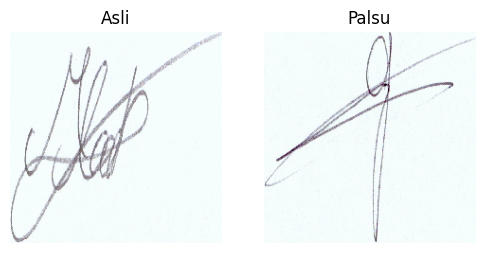

In [ ]:
asli_path = train_df[train_df["label"] == 0]["filepath"].iloc[0]
asli_img = preprocess_image(asli_path)

# Ambil 1 contoh palsu
palsu_path = df[df["label"] == 1]["filepath"].iloc[0]
palsu_img = preprocess_image(palsu_path)

plt.figure(figsize=(6,3))
plt.subplot(1,2,1)
plt.imshow(asli_img)
plt.title("Asli")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(palsu_img)
plt.title("Palsu")
plt.axis("off")
plt.show()

visualisasi data resize

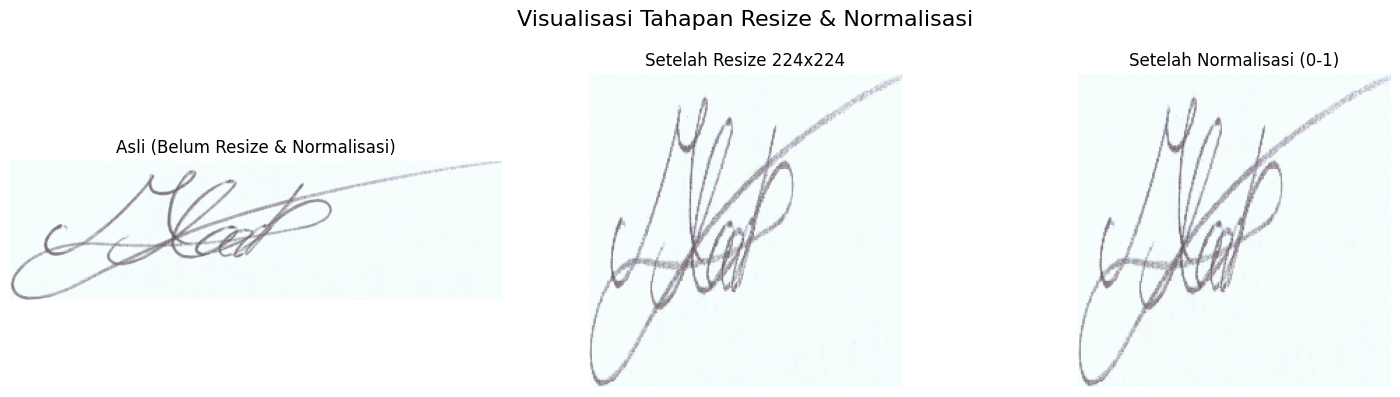

Ukuran asli : (252, 887, 3)
Ukuran setelah resize : (224, 224, 3)
Rentang nilai setelah normalisasi : 0.3019608 sampai 1.0


In [ ]:
# Visualisasi gambar asli, setelah resize, dan setelah normalisasi

import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.preprocessing.image import load_img, img_to_array

# Ambil 1 contoh gambar dari dataset
sample_path = train_df["filepath"].iloc[0]

# Load gambar asli tanpa resize
original_img = load_img(sample_path)

# Gambar setelah resize (belum normalisasi)
resized_img_only = img_to_array(load_img(sample_path, target_size=IMG_SIZE))

# Gambar setelah resize + normalisasi
normalized_img = preprocess_image(sample_path)

# Plot ketiga gambar
plt.figure(figsize=(15, 4))

# Gambar asli
plt.subplot(1, 3, 1)
plt.imshow(original_img)
plt.title("Asli (Belum Resize & Normalisasi)")
plt.axis("off")

# Gambar setelah resize (masih nilai 0–255)
plt.subplot(1, 3, 2)
plt.imshow(resized_img_only.astype("uint8"))
plt.title(f"Setelah Resize {IMG_SIZE[0]}x{IMG_SIZE[1]}")
plt.axis("off")

# Gambar setelah resize & normalisasi (0–1)
plt.subplot(1, 3, 3)
plt.imshow(normalized_img)
plt.title("Setelah Normalisasi (0-1)")
plt.axis("off")

plt.suptitle("Visualisasi Tahapan Resize & Normalisasi", fontsize=16)
plt.tight_layout()
plt.show()

# Info tambahan
print("Ukuran asli :", np.array(original_img).shape)
print("Ukuran setelah resize :", resized_img_only.shape)
print("Rentang nilai setelah normalisasi :", normalized_img.min(), "sampai", normalized_img.max())


Augmentasi data

In [ ]:
# Augmentasi Data 1x per gambar

from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(
    rotation_range=10,       # rotasi ±10 derajat
    width_shift_range=0.1,   # geser horizontal
    height_shift_range=0.1,  # geser vertikal
    zoom_range=0.1,          # zoom in/out
    horizontal_flip=True,    # flip horizontal
    fill_mode='nearest'      # isi piksel kosong
)

datagen.fit(X_train)

n_train = X_train.shape[0]
batch_size = 32

# Siapkan array kosong untuk menampung hasil augmentasi
X_train_aug = np.empty_like(X_train)
y_train_aug = np.empty_like(y_train)

flow = datagen.flow(X_train, y_train, batch_size=batch_size, shuffle=False)

filled = 0
while filled < n_train:
    Xb, yb = next(flow)

    # Hitung sisa yang dibutuhkan
    remain = n_train - filled
    n_batch = min(remain, Xb.shape[0])

    X_train_aug[filled:filled+n_batch] = Xb[:n_batch]
    y_train_aug[filled:filled+n_batch] = yb[:n_batch]

    filled += n_batch
    print(f"Mengisi augmentasi: {filled}/{n_train}", end="\r")

print("\n\nShape X_train asli :", X_train.shape, y_train.shape)
print("Shape X_train_aug  :", X_train_aug.shape, y_train_aug.shape)
print("Total data training setelah augmentasi:", X_train.shape[0] + X_train_aug.shape[0])

Mengisi augmentasi: 1310/1310

Shape X_train asli : (1310, 224, 224, 3) (1310,)
Shape X_train_aug  : (1310, 224, 224, 3) (1310,)
Total data training setelah augmentasi: 2620


Jenis augmentasi yang digunakan:
- Rotasi: ±10°
- Pergeseran horizontal: 10%
- Pergeseran vertikal: 10%
- Zoom: ±10%
- Flip horizontal: Ya
- Fill mode: nearest



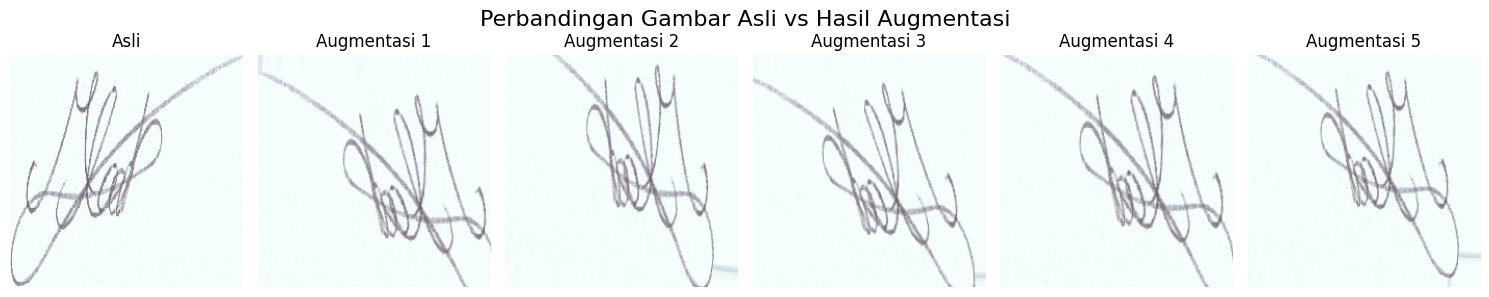

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# menampilkan jenis augmentasi yang digunakan
print("Jenis augmentasi yang digunakan:")
print("- Rotasi: ±10°")
print("- Pergeseran horizontal: 10%")
print("- Pergeseran vertikal: 10%")
print("- Zoom: ±10%")
print("- Flip horizontal: Ya")
print("- Fill mode: nearest\n")

# Pilih satu gambar dari data asli
idx = 0  # kamu bisa ubah indeksnya (0, 1, 2, dst)
original_image = X_train[idx]

# Pastikan gambar dalam rentang 0-1
if original_image.max() > 1:
    original_image = original_image / 255.0

# list untuk menyimpan hasil augmentasi
augmented_images = []

# beberapa augmentasi dari gambar yang sama
num_augmented = 5  # banyaknya versi augmentasi
for i in range(num_augmented):
    aug_img = datagen.random_transform(original_image)
    augmented_images.append(aug_img)

# Plot hasil
plt.figure(figsize=(15, 3))

# Gambar asli
plt.subplot(1, num_augmented + 1, 1)
plt.imshow(original_image)
plt.title("Asli")
plt.axis("off")

# Gambar hasil augmentasi
for i, aug_img in enumerate(augmented_images):
    plt.subplot(1, num_augmented + 1, i + 2)
    plt.imshow(aug_img)
    plt.title(f"Augmentasi {i+1}")
    plt.axis("off")

plt.suptitle("Perbandingan Gambar Asli vs Hasil Augmentasi", fontsize=16)
plt.tight_layout()
plt.show()


# Ekstrkasi fitur dengan MobileNetv2


In [ ]:
# Ekstraksi Fitur dengan MobileNetV2 (original + augmented)

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    pooling='avg',
    input_shape=(224,224,3)
)

print("Model MobileNetV2 berhasil dimuat!")

# Fitur dari gambar ORIGINAL
print("\nEkstraksi fitur training (original)...")
X_train_prep_orig = preprocess_input(X_train * 255.0)
X_test_prep       = preprocess_input(X_test * 255.0)

X_train_feat_orig = base_model.predict(X_train_prep_orig, batch_size=32, verbose=1)
X_test_feat       = base_model.predict(X_test_prep, batch_size=32, verbose=1)

print("Shape fitur train original:", X_train_feat_orig.shape)
print("Shape fitur test          :", X_test_feat.shape)

# Fitur dari gambar AUGMENTED
print("\nEkstraksi fitur training (augmented)...")
X_train_prep_aug = preprocess_input(X_train_aug * 255.0)
X_train_feat_aug = base_model.predict(X_train_prep_aug, batch_size=32, verbose=1)

print("Shape fitur train augmented:", X_train_feat_aug.shape)

# Gabungkan fitur
X_train_feat = np.concatenate([X_train_feat_orig, X_train_feat_aug], axis=0)
y_train_all  = np.concatenate([y_train, y_train_aug], axis=0)

print("\nTOTAL fitur train (original + augmented):", X_train_feat.shape, y_train_all.shape)
print("Fitur test tetap                        :", X_test_feat.shape)

# menampilkan beberapa vektor fitur
print("Contoh fitur train (5 sampel pertama):")
print(X_train_feat[:5])

# Simpan kalau mau dipakai lagi
np.save("X_train_feat.npy", X_train_feat)
np.save("X_test_feat.npy", X_test_feat)
np.save("y_train_all.npy", y_train_all)
np.save("y_test.npy", y_test)

print("\nFitur berhasil diekstraksi dan disimpan!")


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Model MobileNetV2 berhasil dimuat!

Ekstraksi fitur training (original)...
41/41 ━━━━━━━━━━━━━━━━━━━━ 23s 558ms/step
11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 521ms/step
Shape fitur train original: (1310, 1280)
Shape fitur test          : (339, 1280)

Ekstraksi fitur training (augmented)...
41/41 ━━━━━━━━━━━━━━━━━━━━ 22s 535ms/step
Shape fitur train augmented: (1310, 1280)

TOTAL fitur train (original + augmented): (2620, 1280) (2620,)
Fitur test tetap                        : (339, 1280)
Contoh fitur train (5 sampel pertama):
[[0.24596381 0.84534657 0.62965727 ... 0.2770002  0.6096232  2.4827194 ]
 [1.0981419  1.6086161  0.27181205 ... 0.23032302 0.07618282 1.12081   ]
 [0.58404857 0.6090498  1.1424506  ... 0.80603796 0.67323434 1.8550647 ]
 [0.3429061  0.7100151  0.25554645 ... 0.16903535 0.49813598 0.9767731 ]
 [0.2651577  0.5120951  0.12682818 ... 0.15912567 0.19882338 2.4555225 ]]

Fitur berhasil diekstraksi dan disimpan!


# Klasifikasi SVM

**CNN**

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping

# Bentuk CNN kecil (MLP classifier)
model_cnn = models.Sequential([
    layers.Input(shape=(X_train_feat.shape[1],)),   # input = 1280 dimensi
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(1, activation='sigmoid')
])

model_cnn.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model_cnn.summary()

# Early Stopping biar tidak overfitting
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

# Training (PAKAI y_train_all)
history = model_cnn.fit(
    X_train_feat, y_train_all,
    validation_data=(X_test_feat, y_test),
    epochs=50,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

# Evaluasi
loss, acc = model_cnn.evaluate(X_test_feat, y_test, verbose=0)
print(f"\nAkurasi CNN Classifier: {acc:.4f}")


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 360,961 (1.38 MB)

 Trainable params: 360,961 (1.38 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6714 - loss: 0.6492 - val_accuracy: 0.8437 - val_loss: 0.3725
Epoch 2/50
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8417 - loss: 0.3560 - val_accuracy: 0.8230 - val_loss: 0.4689
Epoch 3/50
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8926 - loss: 0.2494 - val_accuracy: 0.8732 - val_loss: 0.3465
Epoch 4/50
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9362 - loss: 0.1727 - val_accuracy: 0.8643 - val_loss: 0.4124
Epoch 5/50
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9342 - loss: 0.1690 - val_accuracy: 0.8496 - val_loss: 0.4441
Epoch 6/50
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9411 - loss: 0.1452 - val_accuracy: 0.8289 - val_loss: 0.5627

Akurasi CNN Classifier: 0.8732


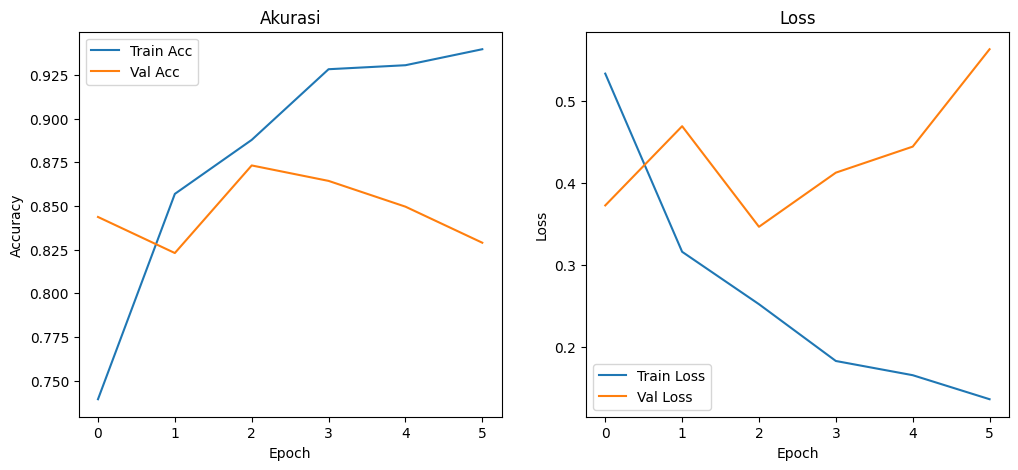

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

# Akurasi
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.title("Akurasi")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Loss
plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()


**SVM**

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import GridSearchCV

pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(probability=True, class_weight="balanced", random_state=42))
])

param_grid = {
    "svm__C": [0.1, 1, 5, 10, 50, 100],
    "svm__gamma": ["scale", "auto", 0.01, 0.001, 0.0001],
    "svm__kernel": ["rbf"]
}

# Grid Search dengan 5-fold CV
print("Melakukan GridSearchCV untuk SVM ...")
grid = GridSearchCV(
    estimator=pipe,
    param_grid=param_grid,
    cv=5,
    verbose=2,
    n_jobs=-1)

grid.fit(X_train_feat, y_train_all)

print("\n GridSearch selesai!")
print("Best Params :", grid.best_params_)
print("Best CV Accuracy :", grid.best_score_)

# Evaluasi di test set
best_svm = grid.best_estimator_
y_pred = best_svm.predict(X_test_feat)

acc = accuracy_score(y_test, y_pred)
print(f"\n Akurasi SVM (Best Model Balanced): {acc:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=["Asli", "Palsu"]))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Melakukan GridSearchCV untuk SVM ...
Fitting 5 folds for each of 30 candidates, totalling 150 fits

 GridSearch selesai!
Best Params : {'svm__C': 5, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}
Best CV Accuracy : 0.966412213740458

 Akurasi SVM (Best Model Balanced): 0.8171

Classification Report:
              precision    recall  f1-score   support

        Asli       0.98      0.69      0.81       191
       Palsu       0.71      0.99      0.82       148

    accuracy                           0.82       339
   macro avg       0.85      0.84      0.82       339
weighted avg       0.86      0.82      0.82       339


Confusion Matrix:
[[131  60]
 [  2 146]]


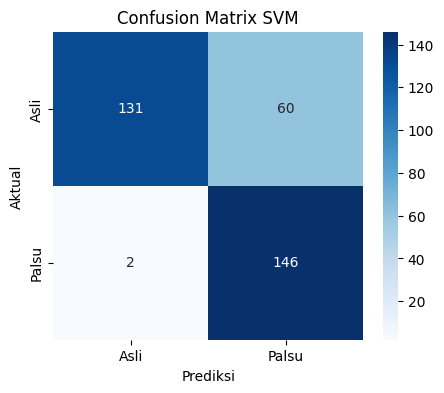

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Asli","Palsu"], yticklabels=["Asli","Palsu"])
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.title("Confusion Matrix SVM")
plt.show()


In [ ]:
# SAVE MODEL

import os
import joblib
import json

SAVE_DIR = "/content/drive/MyDrive/model2_ttd_svm_mnv2"
os.makedirs(SAVE_DIR, exist_ok=True)

joblib.dump(best_svm, os.path.join(SAVE_DIR, "svm_best2.joblib"))
base_model.save(os.path.join(SAVE_DIR, "mobilenetv2_feature_extractor_2.keras"))

metadata = {
    "img_size": [224, 224],
    "label_map": {"0": "Asli", "1": "Palsu"}
}

with open(os.path.join(SAVE_DIR, "metadata2.json"), "w") as f:
    json.dump(metadata, f, indent=2)

print("Model berhasil disimpan ke Google Drive!")
print("Lokasi:", SAVE_DIR)


NameError: name 'best_svm' is not defined

Model berhasil di-load
Ukuran input: (224, 224)
Label: {'0': 'Asli', '1': 'Palsu'}

Klik 'Choose Files' untuk upload gambar tanda tangan


Saving WhatsApp Image 2026-01-10 at 16.53.06.jpeg to WhatsApp Image 2026-01-10 at 16.53.06.jpeg

File: WhatsApp Image 2026-01-10 at 16.53.06.jpeg
Prediksi    : 0 - Asli
Prob Palsu  : 0.4587


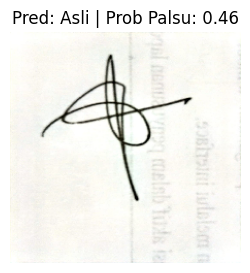

In [ ]:
#TESTING MODEL TO PREDICT

from google.colab import files
import io
import json
import joblib
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# LOAD MODEL
SAVE_DIR = "/content/drive/MyDrive/model2_ttd_svm_mnv2"

svm_model = joblib.load(f"{SAVE_DIR}/svm_best2.joblib")
feature_extractor = tf.keras.models.load_model(
    f"{SAVE_DIR}/mobilenetv2_feature_extractor_2.keras"
)

with open(f"{SAVE_DIR}/metadata2.json", "r") as f:
    metadata = json.load(f)

IMG_SIZE = tuple(metadata["img_size"])
LABEL_MAP = metadata["label_map"]

print("Model berhasil di-load")
print("Ukuran input:", IMG_SIZE)
print("Label:", LABEL_MAP)


# PREPROCESS & EKSTRAKSI FITUR
def extract_feature_from_uploaded_image(image_bytes):
    img = load_img(io.BytesIO(image_bytes), target_size=IMG_SIZE)
    img_array = img_to_array(img).astype("float32") / 255.0

    img_array = np.expand_dims(img_array, axis=0)
    img_array = preprocess_input(img_array * 255.0)

    feature = feature_extractor.predict(img_array, verbose=0)
    return feature


# UPLOAD & PREDIKSI
print("\nKlik 'Choose Files' untuk upload gambar tanda tangan")
uploaded = files.upload()   # <-- tombol Choose File muncul di sini

for filename, image_bytes in uploaded.items():
    print("\nFile:", filename)

    # Ekstraksi fitur
    feat = extract_feature_from_uploaded_image(image_bytes)

    # Prediksi
    pred_label = int(svm_model.predict(feat)[0])
    prob_palsu = svm_model.predict_proba(feat)[0][1]
    label_name = LABEL_MAP[str(pred_label)]

    # Output
    print("Prediksi    :", f"{pred_label} - {label_name}")
    print("Prob Palsu  :", f"{prob_palsu:.4f}")

    # Tampilkan gambar
    img_show = load_img(io.BytesIO(image_bytes), target_size=IMG_SIZE)
    plt.figure(figsize=(3,3))
    plt.imshow(img_show)
    plt.title(f"Pred: {label_name} | Prob Palsu: {prob_palsu:.2f}")
    plt.axis("off")
    plt.show()
